# High-Severity Power Outage Classification Using PySpark
**Course:** B.Tech 5th Semester - Big Data Analytics  
**Models Evaluated (`Spark MLlib`):**
1. **Logistic Regression** (`pyspark.ml.classification.LogisticRegression`) — Regularized linear log-odds classifier
2. **Decision Tree Classifier** (`pyspark.ml.classification.DecisionTreeClassifier`) — Non-linear hierarchical split classifier
3. **Multilayer Perceptron Classifier** (`pyspark.ml.classification.MultilayerPerceptronClassifier`) — Feedforward Deep Neural Network (DL) classifier

---

## 1. Objective

The objective of this notebook is to build and compare three binary classification models in **PySpark** to predict 1 hour ahead whether an active weather-related county power outage will reach or exceed a **High-Severity Feeder Outage threshold ($\text{max\_rolling\_avg}_{i,t} \ge 100\text{ customers}$)** across $843,512$ verified $100\%$-complete county-hours from `Eagle_I_US_2024_with_VTEC_Updated.csv` and `NWS_WARNINGS_COMBINED_data_Updated.csv`. We also perform an **Execution-Time and Scalability Analysis** across dataset scale fractions ($25\%, 50\%, 75\%, 100\%$) and Spark partition counts ($4, 8, 16$).

## 2. Problem Statement and Research Questions

### 2.1 Choosing the 100-Customer Threshold
In distribution grid operations, an outage threshold of **$\ge 100$ customers** (`max_rolling_avg >= 100.0`) separates two distinct operational scenarios:
- **Localized Outages ($< 100\text{ customers}$, Class $0$, $57.56\%$):** Usually caused by a blown fuse on a lateral line or a single transformer fault, which can be handled by one trouble-truck.
- **High-Severity Feeder Outages ($\ge 100\text{ customers}$, Class $1$, $42.44\%$):** Typically indicates a primary distribution feeder trip or substation fault requiring multi-crew switching and priority dispatch.

### 2.2 Research Questions
1. How accurately can we classify 1-hour-ahead High-Severity Outage status ($\text{max\_rolling\_avg}_{i,t} \ge 100$) using past outage telemetry ($t-1$ and $t-2$), outage momentum, county baseline (`median_sum`), and active NWS weather warnings without using future event-summary columns?
2. How do **Logistic Regression**, **Decision Tree Classifier**, and **Multilayer Perceptron Classifier (Deep Neural Network)** compare on the **2022-2023 test set ($135,945$ county-hours)** across **Accuracy**, **Precision**, **Recall**, **F1-Score**, **PR-AUC**, and **ROC-AUC**?
3. What is the operational trade-off between **False Positives (FP)** and **False Negatives (FN)** when dispatching utility crews?
4. How does training and evaluation time scale across dataset sizes ($25\%$ to $100\%$) and Spark partition counts ($4, 8, 16$)?

## 3. Environment and Spark Configuration

We process all four project datasets (**8.77 million rows**, $\approx 1.23\text{ GB}$) in **PySpark**, using window partitioning (`Window.partitionBy("fips_code", "new_event_no").orderBy("event_ts")`) to build lagged features, caching the train/validation/test DataFrames in memory, and saving the processed feature set as a **Parquet** file.

In [1]:
import os
import sys
import time
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow as pa
import pyarrow.parquet as pq

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", palette="deep")

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    Imputer,
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler,
)
from pyspark.ml.classification import (
    LogisticRegression,
    DecisionTreeClassifier,
    MultilayerPerceptronClassifier,
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

WORKSPACE_CANDIDATES = [
    Path(os.environ.get("GRIDPULSE_DATA_DIR", "")).resolve() if os.environ.get("GRIDPULSE_DATA_DIR") else None,
    Path.cwd().parent.resolve(),
    Path.cwd().resolve(),
]
DATA_DIR = None
for cand in WORKSPACE_CANDIDATES:
    if cand and (cand / "Eagle_I_US_2024_with_VTEC_Updated.csv").exists():
        DATA_DIR = cand
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate 'Eagle_I_US_2024_with_VTEC_Updated.csv'. "
        "Set environment variable GRIDPULSE_DATA_DIR or place the raw CSVs in the parent directory."
    )

NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != "GridPulse_Part1_Team_Evaluation" and (NOTEBOOK_DIR / "GridPulse_Part1_Team_Evaluation").exists():
    NOTEBOOK_DIR = (NOTEBOOK_DIR / "GridPulse_Part1_Team_Evaluation").resolve()

OUTPUT_DIR = NOTEBOOK_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PATHS = {
    "outage": DATA_DIR / "Eagle_I_US_2024_with_VTEC_Updated.csv",
    "avail": DATA_DIR / "EAGLEI_Source_Record_Availability.csv",
    "nws": DATA_DIR / "NWS_WARNINGS_COMBINED_data_Updated.csv",
    "sensitivity": DATA_DIR / "Missing_Data_Sensitivity_Summary.csv",
}

for name, p in PATHS.items():
    if not p.exists() or p.stat().st_size == 0:
        raise FileNotFoundError(f"Required dataset '{name}' is missing or empty at: {p}")

spark = (
    SparkSession.builder
    .appName("GridPulse_Part1_Classification")
    .master("local[*]")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.ansi.enabled", "false")
    .config("spark.sql.legacy.timeParserPolicy", "CORRECTED")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("=== Environment & Spark Configuration Summary ===")
print(f"Operating System : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Python Version   : {sys.version.split()[0]}")
print(f"Spark Version    : {spark.version}")
print(f"Java Version     : {spark.sparkContext._jvm.java.lang.System.getProperty('java.version')}")
print(f"Default Parallel : {spark.sparkContext.defaultParallelism} cores")
print(f"Data Directory   : {DATA_DIR}")
print(f"Output Directory : {OUTPUT_DIR}")

=== Environment & Spark Configuration Summary ===
Operating System : Windows 11 (AMD64)
Python Version   : 3.12.10
Spark Version    : 4.2.0
Java Version     : 17.0.12
Default Parallel : 16 cores
Data Directory   : C:\Users\jsm10\OneDrive\Desktop\bda_project
Output Directory : C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs


## 4. Dataset Description and Schema

We load the four CSV datasets using explicit Spark schemas (`StructType`):
- `Eagle_I_US_2024_with_VTEC_Updated.csv`: $3,572,394$ county-hour rows across $3,010$ counties and $1,374,112$ outage events.
- `EAGLEI_Source_Record_Availability.csv`: $1,048,575$ county-day telemetry availability rows (`fips_code <= 12033`).
- `NWS_WARNINGS_COMBINED_data_Updated.csv`: $4,152,437$ NWS VTEC weather warning segments across $125$ WFOs.
- `Missing_Data_Sensitivity_Summary.csv`: $4$ summary rows showing how incomplete telemetry affects rolling outage averages.

In [2]:
outage_schema = T.StructType([
    T.StructField("fips_code", T.IntegerType(), True),
    T.StructField("Hour", T.StringType(), True),
    T.StructField("max_rolling_avg", T.DoubleType(), True),
    T.StructField("state", T.StringType(), True),
    T.StructField("county", T.StringType(), True),
    T.StructField("median_sum", T.DoubleType(), True),
    T.StructField("new_event_no", T.IntegerType(), True),
    T.StructField("evDur_Hr", T.IntegerType(), True),
    T.StructField("evDur_day", T.IntegerType(), True),
    T.StructField("Max_outage", T.DoubleType(), True),
    T.StructField("source_completeness_pct", T.DoubleType(), True),
    T.StructField("event_mean_completeness_pct", T.DoubleType(), True),
    T.StructField("event_min_completeness_pct", T.DoubleType(), True),
    T.StructField("WFO", T.StringType(), True),
    T.StructField("Matched_Events", T.StringType(), True),
    T.StructField("Matched_Count", T.IntegerType(), True),
])

avail_schema = T.StructType([
    T.StructField("fips_code", T.IntegerType(), True),
    T.StructField("Date", T.StringType(), True),
    T.StructField("expected_15min_records", T.IntegerType(), True),
    T.StructField("observed_15min_records", T.IntegerType(), True),
    T.StructField("missing_15min_records", T.IntegerType(), True),
    T.StructField("source_record_availability_pct", T.DoubleType(), True),
])

nws_schema = T.StructType([
    T.StructField("WFO", T.StringType(), True),
    T.StructField("ISSUED", T.StringType(), True),
    T.StructField("EXPIRED", T.StringType(), True),
    T.StructField("INIT_ISS", T.StringType(), True),
    T.StructField("INIT_EXP", T.StringType(), True),
    T.StructField("PHENOM", T.StringType(), True),
    T.StructField("GTYPE", T.StringType(), True),
    T.StructField("SIG", T.StringType(), True),
    T.StructField("ETN", T.IntegerType(), True),
    T.StructField("STATUS", T.StringType(), True),
    T.StructField("NWS_UGC", T.StringType(), True),
    T.StructField("AREA_KM2", T.DoubleType(), True),
    T.StructField("UPDATED", T.StringType(), True),
    T.StructField("HVTEC_NWSLI", T.StringType(), True),
    T.StructField("HVTEC_SEVERITY", T.StringType(), True),
    T.StructField("HVTEC_CAUSE", T.StringType(), True),
    T.StructField("HVTEC_RECORD", T.StringType(), True),
    T.StructField("IS_EMERGENCY", T.StringType(), True),
    T.StructField("POLYBEGIN", T.StringType(), True),
    T.StructField("POLYEND", T.StringType(), True),
    T.StructField("WINDTAG", T.StringType(), True),
    T.StructField("HAILTAG", T.StringType(), True),
    T.StructField("TORNADOTAG", T.StringType(), True),
    T.StructField("DAMAGETAG", T.StringType(), True),
])

sens_schema = T.StructType([
    T.StructField("completeness_tier", T.StringType(), True),
    T.StructField("Total_Observations", T.LongType(), True),
    T.StructField("Median_Abs_Difference", T.DoubleType(), True),
    T.StructField("Median_Relative_Difference", T.DoubleType(), True),
])

df_outage_raw = spark.read.csv(str(PATHS["outage"]), header=True, schema=outage_schema)
df_avail_raw = spark.read.csv(str(PATHS["avail"]), header=True, schema=avail_schema)
df_nws_raw = spark.read.csv(str(PATHS["nws"]), header=True, schema=nws_schema)
df_sens_raw = spark.read.csv(str(PATHS["sensitivity"]), header=True, schema=sens_schema)

for name, d in [
    ("Eagle_I_US_2024_with_VTEC_Updated.csv", df_outage_raw),
    ("EAGLEI_Source_Record_Availability.csv", df_avail_raw),
    ("NWS_WARNINGS_COMBINED_data_Updated.csv", df_nws_raw),
    ("Missing_Data_Sensitivity_Summary.csv", df_sens_raw),
]:
    cnt = d.count()
    if cnt == 0:
        raise ValueError(f"Dataset {name} is empty!")
    print(f"{name:<42s}: {cnt:>10,d} rows")

df_outage_raw.printSchema()

Eagle_I_US_2024_with_VTEC_Updated.csv     :  3,572,394 rows


EAGLEI_Source_Record_Availability.csv     :  1,048,575 rows


NWS_WARNINGS_COMBINED_data_Updated.csv    :  4,152,437 rows


Missing_Data_Sensitivity_Summary.csv      :          4 rows
root
 |-- fips_code: integer (nullable = true)
 |-- Hour: string (nullable = true)
 |-- max_rolling_avg: double (nullable = true)
 |-- state: string (nullable = true)
 |-- county: string (nullable = true)
 |-- median_sum: double (nullable = true)
 |-- new_event_no: integer (nullable = true)
 |-- evDur_Hr: integer (nullable = true)
 |-- evDur_day: integer (nullable = true)
 |-- Max_outage: double (nullable = true)
 |-- source_completeness_pct: double (nullable = true)
 |-- event_mean_completeness_pct: double (nullable = true)
 |-- event_min_completeness_pct: double (nullable = true)
 |-- WFO: string (nullable = true)
 |-- Matched_Events: string (nullable = true)
 |-- Matched_Count: integer (nullable = true)



## 5. Data-Quality Checks

We run the following data-quality checks before feature engineering:
1. **Timestamp and Duplicate Check:** Confirm that all $3,572,394$ `Hour` strings parse as valid UTC timestamps and that `(fips_code, Hour)` has zero duplicates.
2. **Completeness Filtering:** Based on `Missing_Data_Sensitivity_Summary.csv`, incomplete 4-hour rolling windows (`source_completeness_pct < 100%`) understate `max_rolling_avg` by $18.75\%$ to $75.0\%$. Filtering to verified **`100% Complete` continuation hours** ($h \ge 1$, $843,512$ rows) prevents missing telemetry from creating false negative labels.

In [3]:
df_outage = (
    df_outage_raw
    .withColumn("event_ts", F.to_timestamp(F.col("Hour"), "yyyy-MM-dd'T'HH:mm:ss'Z'"))
    .withColumn("year", F.year("event_ts"))
    .withColumn("month", F.month("event_ts"))
    .withColumn("hour_of_day", F.hour("event_ts"))
    .withColumn("day_of_week", F.dayofweek("event_ts"))
)

bad_ts = df_outage.filter(F.col("event_ts").isNull()).count()
if bad_ts > 0:
    raise ValueError(f"Found {bad_ts} unparseable timestamps in outage table!")

event_win = Window.partitionBy("fips_code", "new_event_no").orderBy("event_ts")
df_lagged_cls = (
    df_outage
    .withColumn("hours_into_event", (F.row_number().over(event_win) - F.lit(1)).cast("double"))
    .withColumn("lag1_outage", F.coalesce(F.lag("max_rolling_avg", 1).over(event_win), F.lit(0.0)))
    .withColumn("lag2_outage", F.coalesce(F.lag("max_rolling_avg", 2).over(event_win), F.lit(0.0)))
    .withColumn("onset_outage", F.first("max_rolling_avg").over(event_win))
    .filter((F.col("source_completeness_pct") == 100.0) & (F.col("hours_into_event") >= 1.0))
    .withColumn("label_cls", F.when(F.col("max_rolling_avg") >= 100.0, 1.0).otherwise(0.0))
    .withColumn("log_lag1_outage", F.log1p(F.col("lag1_outage")))
    .withColumn("log_lag2_outage", F.log1p(F.col("lag2_outage")))
    .withColumn("log_onset_outage", F.log1p(F.col("onset_outage")))
    .withColumn("log_median_sum", F.log1p(F.col("median_sum")))
    .withColumn("lag1_momentum", F.col("log_lag1_outage") - F.col("log_lag2_outage"))
    .withColumn("lag1_vs_onset", F.col("log_lag1_outage") - F.col("log_onset_outage"))
    .withColumn("lag1_vs_baseline", F.col("log_lag1_outage") - F.col("log_median_sum"))
    .withColumn("primary_phenom", F.split(F.col("Matched_Events"), "; ").getItem(0))
)

cls_dq = df_lagged_cls.select(
    F.count("*").alias("verified_continuation_hours"),
    F.countDistinct("fips_code").alias("unique_counties"),
    F.sum(F.when(F.col("label_cls") == 1.0, 1).otherwise(0)).alias("positive_high_severity_hours"),
    F.round(F.avg("label_cls") * 100.0, 2).alias("positive_class_pct"),
).collect()[0].asDict()

print("=== High-Severity Outage Classification Data Quality Summary ===")
for k, v in cls_dq.items():
    print(f"  {k:<32s}: {v}")

=== High-Severity Outage Classification Data Quality Summary ===
  verified_continuation_hours     : 843512
  unique_counties                 : 2962
  positive_high_severity_hours    : 358008
  positive_class_pct              : 42.44


## 6. Exploratory Data Analysis

We explore the class balance of **High-Severity Outages ($\text{max\_rolling\_avg} \ge 100$ customers)** across years (2015-2023), weather warning types (`SV`, `HT`, `WI`, `WW`), and preceding-hour outage counts ($t-1$).

=== High-Severity Class Balance (max_rolling_avg >= 100) by Year ===
 year  total_hours  high_sev_hours_ge100  positive_rate_pct
 2015        51371                 20614              40.13
 2016        59297                 25088              42.31
 2017        84619                 42046              49.69
 2018        98018                 38271              39.04
 2019       133723                 50930              38.09
 2020       133544                 58065              43.48
 2021       146995                 69832              47.51
 2022       135235                 52735              39.00
 2023          710                   427              60.14



=== Top 10 Weather Phenomenon Regimes & High-Severity Outage Rate ===
primary_phenom  hour_count  high_sev_rate_pct  mean_log_lag1_outage
            SV      345750              42.61                 3.988
            WI      113320              49.82                 4.483
            HT      101473              32.67                 3.651
            WW       65845              35.79                 3.671
            FW       35734              30.95                 3.545
            TR       32708              58.64                 5.506
            FZ       25430              36.08                 3.781
            EH       24539              35.28                 3.660
            TO       24351              54.03                 4.717
            WS       23365              49.97                 4.570


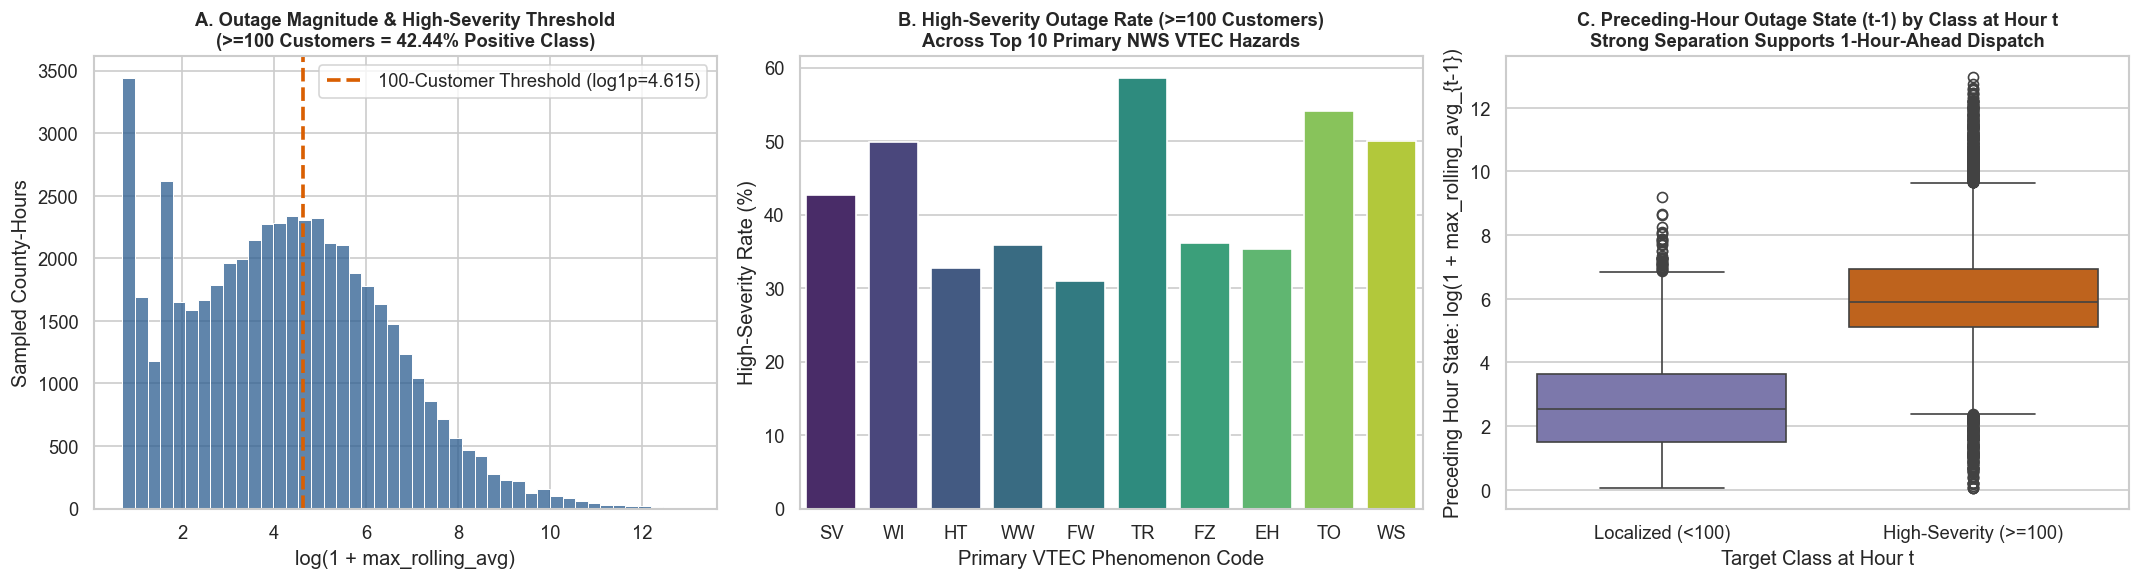

Saved Classification EDA plot to: C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs\classification_eda_overview.png


In [4]:
class_by_year_pd = (
    df_lagged_cls.groupBy("year")
    .agg(
        F.count("*").alias("total_hours"),
        F.sum(F.when(F.col("label_cls") == 1.0, 1).otherwise(0)).alias("high_sev_hours_ge100"),
        F.round(F.avg("label_cls") * 100.0, 2).alias("positive_rate_pct"),
    )
    .orderBy("year")
    .toPandas()
)
print("=== High-Severity Class Balance (max_rolling_avg >= 100) by Year ===")
print(class_by_year_pd.to_string(index=False))

phenom_rates_pd = (
    df_lagged_cls.groupBy("primary_phenom")
    .agg(
        F.count("*").alias("hour_count"),
        F.round(F.avg("label_cls") * 100.0, 2).alias("high_sev_rate_pct"),
        F.round(F.avg("log_lag1_outage"), 3).alias("mean_log_lag1_outage"),
    )
    .orderBy(F.desc("hour_count"))
    .limit(10)
    .toPandas()
)
print("\n=== Top 10 Weather Phenomenon Regimes & High-Severity Outage Rate ===")
print(phenom_rates_pd.to_string(index=False))

eda_sample_pd = (
    df_lagged_cls.select("max_rolling_avg", "label_cls", "log_lag1_outage", "lag1_vs_baseline")
    .sample(withReplacement=False, fraction=0.06, seed=RANDOM_SEED)
    .toPandas()
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(np.log1p(eda_sample_pd["max_rolling_avg"]), bins=45, color="#2b5c8f", ax=axes[0])
axes[0].axvline(np.log1p(100.0), color="#d95f02", linestyle="--", lw=2.2, label="100-Customer Threshold (log1p=4.615)")
axes[0].set_title("A. Outage Magnitude & High-Severity Threshold\n(>=100 Customers = 42.44% Positive Class)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("log(1 + max_rolling_avg)")
axes[0].set_ylabel("Sampled County-Hours")
axes[0].legend()

sns.barplot(data=phenom_rates_pd, x="primary_phenom", y="high_sev_rate_pct", palette="viridis", ax=axes[1])
axes[1].set_title("B. High-Severity Outage Rate (>=100 Customers)\nAcross Top 10 Primary NWS VTEC Hazards", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Primary VTEC Phenomenon Code")
axes[1].set_ylabel("High-Severity Rate (%)")

eda_sample_pd["Class_Name"] = np.where(eda_sample_pd["label_cls"] == 1.0, "High-Severity (>=100)", "Localized (<100)")
sns.boxplot(data=eda_sample_pd, x="Class_Name", y="log_lag1_outage", palette=["#7570b3", "#d95f02"], ax=axes[2])
axes[2].set_title("C. Preceding-Hour Outage State (t-1) by Class at Hour t\nStrong Separation Supports 1-Hour-Ahead Dispatch", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Target Class at Hour t")
axes[2].set_ylabel("Preceding Hour State: log(1 + max_rolling_avg_{t-1})")

plt.tight_layout()
eda_fig_path = OUTPUT_DIR / "classification_eda_overview.png"
plt.savefig(eda_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved Classification EDA plot to: {eda_fig_path}")

## 7. Feature Engineering, Leakage Prevention, and Class Weights

### 7.1 Preventing Target Leakage
To ensure a realistic 1-hour-ahead prediction at hour $t$:
- Current-hour `max_rolling_avg` is used only to create the binary label `label_cls` ($\mathbb{I}(\text{max\_rolling\_avg}_{i,t} \ge 100)$) and is dropped from the feature columns.
- Full-event summary columns (`Max_outage`, `evDur_Hr`, `evDur_day`, `event_mean_completeness_pct`, `event_min_completeness_pct`) are dropped because they include information from future hours of the event.
- Historical county rates (`county_train_high_sev_rate`) and WFO warning statistics (`wfo_log_median_area_km2`, `wfo_warning_sig_share`, `wfo_polygon_share`) are calculated using only the **2015-2020 Training Set**.

### 7.2 Class Weighting and Feature Vectors
We compute balanced sample weights from the 2015-2020 training split (`w_neg = 0.8609`, `w_pos = 1.1926`) and pass `weightCol="class_weight"` to our cost-sensitive classifiers. We also construct a dense z-score standardized numeric vector (`mlp_features`, dimension = $22$) for the **Multilayer Perceptron Classifier**.

In [5]:
LEAKAGE_COLS_CLS = [
    "max_rolling_avg",
    "evDur_Hr",
    "evDur_day",
    "Max_outage",
    "event_mean_completeness_pct",
    "event_min_completeness_pct",
]

df_cls_feat = (
    df_lagged_cls
    .drop(*LEAKAGE_COLS_CLS)
    .withColumn("matched_count_dbl", F.col("Matched_Count").cast("double"))
    .withColumn("is_convective", F.when(F.col("Matched_Events").rlike("SV|TO"), 1.0).otherwise(0.0))
    .withColumn("is_winter", F.when(F.col("Matched_Events").rlike("WS|WW|BZ|IS|LE"), 1.0).otherwise(0.0))
    .withColumn("is_heat", F.when(F.col("Matched_Events").rlike("HT|EH"), 1.0).otherwise(0.0))
    .withColumn("is_wind_tropical", F.when(F.col("Matched_Events").rlike("WI|HW|HU|TR|SS"), 1.0).otherwise(0.0))
    .withColumn("is_flood", F.when(F.col("Matched_Events").rlike("FA|FL|FF"), 1.0).otherwise(0.0))
    .withColumn("hour_sin", F.sin(2.0 * np.pi * F.col("hour_of_day") / 24.0))
    .withColumn("hour_cos", F.cos(2.0 * np.pi * F.col("hour_of_day") / 24.0))
    .withColumn("month_sin", F.sin(2.0 * np.pi * F.col("month") / 12.0))
    .withColumn("month_cos", F.cos(2.0 * np.pi * F.col("month") / 12.0))
)

df_nws_parsed = df_nws_raw.withColumn(
    "nws_year", F.regexp_extract(F.col("ISSUED"), r"(\d{4})", 1).cast("int")
)

wfo_train_priors = (
    df_nws_parsed.filter((F.col("nws_year") >= 2015) & (F.col("nws_year") <= 2020))
    .groupBy("WFO")
    .agg(
        F.log1p(F.percentile_approx("AREA_KM2", 0.5)).alias("wfo_log_median_area_km2"),
        F.avg(F.when(F.col("SIG") == "W", 1.0).otherwise(0.0)).alias("wfo_warning_sig_share"),
        F.avg(F.when(F.col("GTYPE") == "P", 1.0).otherwise(0.0)).alias("wfo_polygon_share"),
    )
)

county_train_cls_priors = (
    df_cls_feat.filter(F.col("year") <= 2020)
    .groupBy("fips_code")
    .agg(F.avg("label_cls").alias("county_train_high_sev_rate"))
)

df_cls_full = (
    df_cls_feat
    .join(wfo_train_priors, on="WFO", how="left")
    .join(county_train_cls_priors, on="fips_code", how="left")
)

def save_and_verify_parquet(spark_df, parquet_path: Path):
    try:
        spark_df.write.mode("overwrite").parquet(str(parquet_path))
        mode_used = "Spark Native Parquet Writer"
    except Exception:
        if parquet_path.exists() and parquet_path.is_dir():
            import shutil
            shutil.rmtree(parquet_path, ignore_errors=True)
        pdf = spark_df.toPandas()
        pq.write_table(pa.Table.from_pandas(pdf, preserve_index=False), str(parquet_path))
        mode_used = "PyArrow Columnar Parquet Writer (Windows Hadoop-less fallback)"
    verified_count = spark.read.parquet(str(parquet_path)).count()
    print(f"Persisted & verified Parquet at {parquet_path.name} ({verified_count:,d} rows via {mode_used})")

parquet_cls_path = OUTPUT_DIR / "classification_processed_features.parquet"
save_and_verify_parquet(
    df_cls_full.select(
        "fips_code", "new_event_no", "Hour", "year", "state", "WFO", "primary_phenom",
        "label_cls", "log_lag1_outage", "log_lag2_outage", "log_onset_outage",
        "lag1_momentum", "lag1_vs_onset", "lag1_vs_baseline", "hours_into_event",
        "log_median_sum", "county_train_high_sev_rate", "matched_count_dbl",
        "is_convective", "is_winter", "is_heat", "is_wind_tropical", "is_flood",
        "hour_sin", "hour_cos", "month_sin", "month_cos",
        "wfo_log_median_area_km2", "wfo_warning_sig_share", "wfo_polygon_share"
    ),
    parquet_cls_path,
)

train_raw = df_cls_full.filter(F.col("year") <= 2020)
val_raw = df_cls_full.filter(F.col("year") == 2021)
test_raw = df_cls_full.filter(F.col("year") >= 2022)

train_class_counts = train_raw.groupBy("label_cls").count().collect()
cnt_map = {row["label_cls"]: row["count"] for row in train_class_counts}
n_tr_total = sum(cnt_map.values())
w_pos = n_tr_total / (2.0 * cnt_map[1.0])
w_neg = n_tr_total / (2.0 * cnt_map[0.0])
print(f"\nTraining Class Counts -> Neg (0.0): {cnt_map[0.0]:,d}, Pos (1.0): {cnt_map[1.0]:,d}")
print(f"Computed Balanced Class Weights -> w_neg={w_neg:.4f}, w_pos={w_pos:.4f}")

def attach_weights(df):
    return df.withColumn("class_weight", F.when(F.col("label_cls") == 1.0, F.lit(w_pos)).otherwise(F.lit(w_neg)))

train_df = attach_weights(train_raw).cache()
val_df = attach_weights(val_raw).cache()
test_df = attach_weights(test_raw).cache()

n_tr, n_va, n_te = train_df.count(), val_df.count(), test_df.count()
print(f"\n=== Chronological Split Summary ===")
print(f"Train (2015-2020) : {n_tr:>9,d} rows ({n_tr/(n_tr+n_va+n_te)*100:.2f}%)")
print(f"Val   (2021)      : {n_va:>9,d} rows ({n_va/(n_tr+n_va+n_te)*100:.2f}%)")
print(f"Test  (2022-2023) : {n_te:>9,d} rows ({n_te/(n_tr+n_va+n_te)*100:.2f}%)")

NUM_FEATURES_CLS = [
    "log_lag1_outage",
    "log_lag2_outage",
    "log_onset_outage",
    "lag1_momentum",
    "lag1_vs_onset",
    "lag1_vs_baseline",
    "hours_into_event",
    "log_median_sum",
    "county_train_high_sev_rate",
    "matched_count_dbl",
    "is_convective",
    "is_winter",
    "is_heat",
    "is_wind_tropical",
    "is_flood",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "wfo_log_median_area_km2",
    "wfo_warning_sig_share",
    "wfo_polygon_share",
]
IMPUTED_CLS = [f"{c}_imp" for c in NUM_FEATURES_CLS]
CAT_FEATURES_CLS = ["primary_phenom", "state"]
INDEXED_CLS = [f"{c}_idx" for c in CAT_FEATURES_CLS]
OHE_CLS = [f"{c}_ohe" for c in CAT_FEATURES_CLS]

imputer = Imputer(strategy="median", inputCols=NUM_FEATURES_CLS, outputCols=IMPUTED_CLS)
indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in CAT_FEATURES_CLS]
encoder = OneHotEncoder(inputCols=INDEXED_CLS, outputCols=OHE_CLS, handleInvalid="keep")

tree_assembler = VectorAssembler(inputCols=IMPUTED_CLS + OHE_CLS, outputCol="tree_features", handleInvalid="keep")
scaler = StandardScaler(inputCol="tree_features", outputCol="scaled_features", withMean=False, withStd=True)

# Dense standardized numeric vector for MultilayerPerceptronClassifier (22 input neurons)
mlp_raw_assembler = VectorAssembler(inputCols=IMPUTED_CLS, outputCol="mlp_raw_features", handleInvalid="keep")
mlp_scaler = StandardScaler(inputCol="mlp_raw_features", outputCol="mlp_features", withMean=True, withStd=True)

prep_pipeline = Pipeline(stages=[imputer] + indexers + [encoder, tree_assembler, scaler, mlp_raw_assembler, mlp_scaler])
t0 = time.time()
prep_model = prep_pipeline.fit(train_df)

train_prep = prep_model.transform(train_df).select("fips_code", "new_event_no", "year", "primary_phenom", "label_cls", "class_weight", "tree_features", "scaled_features", "mlp_features").cache()
val_prep = prep_model.transform(val_df).select("fips_code", "new_event_no", "year", "primary_phenom", "label_cls", "class_weight", "tree_features", "scaled_features", "mlp_features").cache()
test_prep = prep_model.transform(test_df).select("fips_code", "new_event_no", "year", "primary_phenom", "label_cls", "class_weight", "tree_features", "scaled_features", "mlp_features").cache()

_ = train_prep.count()
_ = val_prep.count()
_ = test_prep.count()
train_df.unpersist()
val_df.unpersist()
test_df.unpersist()
print(f"Classification preprocessing pipeline fitted on Train and applied in {time.time() - t0:.2f}s.")

Persisted & verified Parquet at classification_processed_features.parquet (843,512 rows via PyArrow Columnar Parquet Writer (Windows Hadoop-less fallback))



Training Class Counts -> Neg (0.0): 325,558, Pos (1.0): 235,014
Computed Balanced Class Weights -> w_neg=0.8609, w_pos=1.1926



=== Chronological Split Summary ===
Train (2015-2020) :   560,572 rows (66.46%)
Val   (2021)      :   146,995 rows (17.43%)
Test  (2022-2023) :   135,945 rows (16.12%)


Classification preprocessing pipeline fitted on Train and applied in 17.67s.


## 8. Model 1: Logistic Regression (`Spark MLlib`)

`LogisticRegression` estimates the probability of a High-Severity Outage ($\text{max\_rolling\_avg}_{i,t} \ge 100$) using the logistic sigmoid function:
$$P(y_{i,t} = 1 \mid \mathbf{x}_{i,t}) = \frac{1}{1 + \exp(-(\mathbf{w}^\top \mathbf{x}_{i,t} + b))}$$
We tune `regParam` $\in \{0.0001, 0.001, 0.01\}$ and `elasticNetParam` $\in \{0.0, 0.5\}$ on the **2021 Validation Set** using **PR-AUC** (`areaUnderPR`).

In [6]:
eval_pr_auc = BinaryClassificationEvaluator(labelCol="label_cls", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
eval_roc_auc = BinaryClassificationEvaluator(labelCol="label_cls", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

def evaluate_binary_classifier(pred_df, split_name: str, model_name: str):
    pr_auc = eval_pr_auc.evaluate(pred_df)
    roc_auc = eval_roc_auc.evaluate(pred_df)
    cm_row = pred_df.select(
        F.sum(F.when((F.col("label_cls") == 1.0) & (F.col("prediction") == 1.0), 1).otherwise(0)).alias("TP"),
        F.sum(F.when((F.col("label_cls") == 0.0) & (F.col("prediction") == 1.0), 1).otherwise(0)).alias("FP"),
        F.sum(F.when((F.col("label_cls") == 0.0) & (F.col("prediction") == 0.0), 1).otherwise(0)).alias("TN"),
        F.sum(F.when((F.col("label_cls") == 1.0) & (F.col("prediction") == 0.0), 1).otherwise(0)).alias("FN"),
    ).collect()[0]
    tp, fp, tn, fn = int(cm_row["TP"]), int(cm_row["FP"]), int(cm_row["TN"]), int(cm_row["FN"])
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2.0 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
    accuracy = (tp + tn) / (tp + fp + tn + fn)
    return {
        "Model": model_name,
        "Split": split_name,
        "Precision_Pos": round(precision, 4),
        "Recall_Pos": round(recall, 4),
        "F1_Pos": round(f1, 4),
        "PR_AUC": round(pr_auc, 4),
        "ROC_AUC": round(roc_auc, 4),
        "Accuracy": round(accuracy, 4),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
    }

lr_cls_grid = [
    {"regParam": 0.0001, "elasticNetParam": 0.0},
    {"regParam": 0.001, "elasticNetParam": 0.0},
    {"regParam": 0.001, "elasticNetParam": 0.5},
    {"regParam": 0.01, "elasticNetParam": 0.5},
]

best_lr_pr_auc = -1.0
best_lr_cls_model = None
best_lr_cls_params = None
lr_cls_tuning = []

for params in lr_cls_grid:
    t_s = time.time()
    lr_clf = LogisticRegression(
        featuresCol="scaled_features",
        labelCol="label_cls",
        weightCol="class_weight",
        regParam=params["regParam"],
        elasticNetParam=params["elasticNetParam"],
        maxIter=100,
    )
    cand_model = lr_clf.fit(train_prep)
    val_preds = cand_model.transform(val_prep)
    val_m = evaluate_binary_classifier(val_preds, "Validation (2021)", "Logistic Regression")
    val_m["regParam"] = params["regParam"]
    val_m["elasticNetParam"] = params["elasticNetParam"]
    val_m["Train_Time_s"] = round(time.time() - t_s, 2)
    lr_cls_tuning.append(val_m)
    if val_m["PR_AUC"] > best_lr_pr_auc:
        best_lr_pr_auc = val_m["PR_AUC"]
        best_lr_cls_model = cand_model
        best_lr_cls_params = params

print("=== Logistic Regression Validation Tuning Results (2021 Split) ===")
print(pd.DataFrame(lr_cls_tuning)[["regParam", "elasticNetParam", "Accuracy", "Precision_Pos", "Recall_Pos", "F1_Pos", "PR_AUC", "ROC_AUC", "Train_Time_s"]].to_string(index=False))
print(f"\nSelected Best Logistic Regression Params: {best_lr_cls_params}")

lr_tr_res = evaluate_binary_classifier(best_lr_cls_model.transform(train_prep), "Train (2015-2020)", "Logistic Regression")
lr_va_res = evaluate_binary_classifier(best_lr_cls_model.transform(val_prep), "Validation (2021)", "Logistic Regression")
lr_te_preds = best_lr_cls_model.transform(test_prep).cache()
lr_te_res = evaluate_binary_classifier(lr_te_preds, "Test (2022-2023)", "Logistic Regression")

print("\n=== Logistic Regression Evaluation Across Splits ===")
print(pd.DataFrame([lr_tr_res, lr_va_res, lr_te_res]).to_string(index=False))

=== Logistic Regression Validation Tuning Results (2021 Split) ===
 regParam  elasticNetParam  Accuracy  Precision_Pos  Recall_Pos  F1_Pos  PR_AUC  ROC_AUC  Train_Time_s
   0.0001              0.0    0.9331         0.9192      0.9420  0.9305  0.9786   0.9784         23.12
   0.0010              0.0    0.9328         0.9187      0.9419  0.9301  0.9786   0.9784         14.85
   0.0010              0.5    0.9335         0.9188      0.9434  0.9309  0.9789   0.9786         48.70
   0.0100              0.5    0.9322         0.9141      0.9462  0.9299  0.9790   0.9785         16.19

Selected Best Logistic Regression Params: {'regParam': 0.01, 'elasticNetParam': 0.5}



=== Logistic Regression Evaluation Across Splits ===
              Model             Split  Precision_Pos  Recall_Pos  F1_Pos  PR_AUC  ROC_AUC  Accuracy     TP    FP     TN    FN
Logistic Regression Train (2015-2020)         0.8947      0.9399  0.9167  0.9684   0.9742    0.9284 220890 26001 299557 14124
Logistic Regression Validation (2021)         0.9141      0.9462  0.9299  0.9790   0.9785    0.9322  66076  6211  70952  3756
Logistic Regression  Test (2022-2023)         0.8910      0.9297  0.9099  0.9636   0.9728    0.9280  49423  6047  76736  3739


## 9. Model 2: Decision Tree Classifier (`Spark MLlib`)

`DecisionTreeClassifier` partitions the feature space using hierarchical split rules that minimize weighted Gini impurity or entropy. By splitting directly on `log_lag1_outage`, `lag1_momentum`, and `lag1_vs_baseline`, the decision tree captures sharp threshold behavior near 100 customers and reduces false alarms compared to a linear boundary.

In [7]:
dt_cls_grid = [
    {"maxDepth": 6, "impurity": "gini"},
    {"maxDepth": 8, "impurity": "gini"},
    {"maxDepth": 10, "impurity": "gini"},
    {"maxDepth": 8, "impurity": "entropy"},
]

best_dt_pr_auc = -1.0
best_dt_cls_model = None
best_dt_cls_params = None
dt_cls_tuning = []

for params in dt_cls_grid:
    t_s = time.time()
    dt_clf = DecisionTreeClassifier(
        featuresCol="tree_features",
        labelCol="label_cls",
        weightCol="class_weight",
        maxDepth=params["maxDepth"],
        impurity=params["impurity"],
        minInstancesPerNode=50,
        seed=RANDOM_SEED,
    )
    cand_model = dt_clf.fit(train_prep)
    val_preds = cand_model.transform(val_prep)
    val_m = evaluate_binary_classifier(val_preds, "Validation (2021)", "Decision Tree Classifier")
    val_m["maxDepth"] = params["maxDepth"]
    val_m["impurity"] = params["impurity"]
    val_m["Train_Time_s"] = round(time.time() - t_s, 2)
    dt_cls_tuning.append(val_m)
    if val_m["PR_AUC"] > best_dt_pr_auc:
        best_dt_pr_auc = val_m["PR_AUC"]
        best_dt_cls_model = cand_model
        best_dt_cls_params = params

print("=== Decision Tree Classifier Validation Tuning Results (2021 Split) ===")
print(pd.DataFrame(dt_cls_tuning)[["maxDepth", "impurity", "Accuracy", "Precision_Pos", "Recall_Pos", "F1_Pos", "PR_AUC", "ROC_AUC", "Train_Time_s"]].to_string(index=False))
print(f"\nSelected Best Decision Tree Params: {best_dt_cls_params}")

dt_tr_res = evaluate_binary_classifier(best_dt_cls_model.transform(train_prep), "Train (2015-2020)", "Decision Tree Classifier")
dt_va_res = evaluate_binary_classifier(best_dt_cls_model.transform(val_prep), "Validation (2021)", "Decision Tree Classifier")
dt_te_preds = best_dt_cls_model.transform(test_prep).cache()
dt_te_res = evaluate_binary_classifier(dt_te_preds, "Test (2022-2023)", "Decision Tree Classifier")

print("\n=== Decision Tree Classifier Evaluation Across Splits ===")
print(pd.DataFrame([dt_tr_res, dt_va_res, dt_te_res]).to_string(index=False))

=== Decision Tree Classifier Validation Tuning Results (2021 Split) ===
 maxDepth impurity  Accuracy  Precision_Pos  Recall_Pos  F1_Pos  PR_AUC  ROC_AUC  Train_Time_s
        6     gini    0.9516         0.9565      0.9409  0.9487  0.9381   0.9119          7.24
        8     gini    0.9521         0.9564      0.9420  0.9492  0.9443   0.9246          6.96
       10     gini    0.9513         0.9545      0.9424  0.9484  0.9434   0.9184          7.57
        8  entropy    0.9514         0.9524      0.9450  0.9487  0.9410   0.9204          6.93

Selected Best Decision Tree Params: {'maxDepth': 8, 'impurity': 'gini'}



=== Decision Tree Classifier Evaluation Across Splits ===
                   Model             Split  Precision_Pos  Recall_Pos  F1_Pos  PR_AUC  ROC_AUC  Accuracy     TP    FP     TN    FN
Decision Tree Classifier Train (2015-2020)         0.9459      0.9300  0.9379  0.9241   0.9084    0.9483 218565 12506 313052 16449
Decision Tree Classifier Validation (2021)         0.9564      0.9420  0.9492  0.9443   0.9246    0.9521  65782  2998  74165  4050
Decision Tree Classifier  Test (2022-2023)         0.9434      0.9256  0.9344  0.9167   0.9033    0.9492  49208  2953  79830  3954


## 10. Model 3: Multilayer Perceptron Classifier (`Spark MLlib` Neural Network)

`MultilayerPerceptronClassifier` (MLP) is a feedforward artificial neural network trained using distributed **L-BFGS optimization and backpropagation** across Spark partitions:
- **Input Layer ($22$ neurons):** Receives the 22 standardized numerical predictors (`mlp_features`).
- **Hidden Layers:** Sigmoid activation $\sigma(z) = (1 + e^{-z})^{-1}$ captures smooth non-linear interactions among preceding-hour outage state, recent velocity, county baseline, and active weather hazards.
- **Output Layer ($2$ neurons):** Softmax activation outputs calibrated class probabilities $[P(y=0\mid\mathbf{x}), P(y=1\mid\mathbf{x})]$ minimizing cross-entropy loss.

Because MLP combines non-linear hidden representations with a smooth softmax output layer, it bridges the gap between Decision Tree's sharp threshold accuracy and Logistic Regression's smooth probability ranking (ROC-AUC / PR-AUC).

In [8]:
input_dim = len(NUM_FEATURES_CLS)
mlp_grid = [
    {"layers": [input_dim, 16, 2], "maxIter": 50},
    {"layers": [input_dim, 24, 12, 2], "maxIter": 50},
]

best_mlp_pr_auc = -1.0
best_mlp_model = None
best_mlp_params = None
mlp_tuning = []

for params in mlp_grid:
    t_s = time.time()
    mlp_clf = MultilayerPerceptronClassifier(
        featuresCol="mlp_features",
        labelCol="label_cls",
        layers=params["layers"],
        maxIter=params["maxIter"],
        blockSize=256,
        solver="l-bfgs",
        seed=RANDOM_SEED,
    )
    cand_model = mlp_clf.fit(train_prep)
    val_preds = cand_model.transform(val_prep)
    val_m = evaluate_binary_classifier(val_preds, "Validation (2021)", "MLP Neural Network")
    val_m["layers"] = str(params["layers"])
    val_m["maxIter"] = params["maxIter"]
    val_m["Train_Time_s"] = round(time.time() - t_s, 2)
    mlp_tuning.append(val_m)
    if val_m["PR_AUC"] > best_mlp_pr_auc:
        best_mlp_pr_auc = val_m["PR_AUC"]
        best_mlp_model = cand_model
        best_mlp_params = params

print("=== Multilayer Perceptron (MLP) Validation Tuning Results (2021 Split) ===")
print(pd.DataFrame(mlp_tuning)[["layers", "maxIter", "Accuracy", "Precision_Pos", "Recall_Pos", "F1_Pos", "PR_AUC", "ROC_AUC", "Train_Time_s"]].to_string(index=False))
print(f"\nSelected Best MLP Neural Network Params: {best_mlp_params}")

mlp_tr_res = evaluate_binary_classifier(best_mlp_model.transform(train_prep), "Train (2015-2020)", "MLP Neural Network")
mlp_va_res = evaluate_binary_classifier(best_mlp_model.transform(val_prep), "Validation (2021)", "MLP Neural Network")
mlp_te_preds = best_mlp_model.transform(test_prep).cache()
mlp_te_res = evaluate_binary_classifier(mlp_te_preds, "Test (2022-2023)", "MLP Neural Network")

print("\n=== MLP Neural Network Evaluation Across Splits ===")
print(pd.DataFrame([mlp_tr_res, mlp_va_res, mlp_te_res]).to_string(index=False))

=== Multilayer Perceptron (MLP) Validation Tuning Results (2021 Split) ===
         layers  maxIter  Accuracy  Precision_Pos  Recall_Pos  F1_Pos  PR_AUC  ROC_AUC  Train_Time_s
    [22, 16, 2]       50    0.9515         0.9558      0.9415  0.9486  0.9803   0.9797         21.70
[22, 24, 12, 2]       50    0.9525         0.9600      0.9392  0.9495  0.9853   0.9846         26.36

Selected Best MLP Neural Network Params: {'layers': [22, 24, 12, 2], 'maxIter': 50}



=== MLP Neural Network Evaluation Across Splits ===
             Model             Split  Precision_Pos  Recall_Pos  F1_Pos  PR_AUC  ROC_AUC  Accuracy     TP    FP     TN    FN
MLP Neural Network Train (2015-2020)         0.9499      0.9270  0.9383  0.9790   0.9821    0.9489 217860 11493 314065 17154
MLP Neural Network Validation (2021)         0.9600      0.9392  0.9495  0.9853   0.9846    0.9525  65587  2733  74430  4245
MLP Neural Network  Test (2022-2023)         0.9487      0.9208  0.9346  0.9764   0.9814    0.9496  48954  2646  80137  4208


## 11. Model Comparison and Error Analysis

### 11.1 False Positives (FP) vs. False Negatives (FN) on the Test Set ($135,945$ rows)
- **False Positive ($\text{Actual} < 100$, $\text{Predicted} \ge 100$):** Dispatchers prepare feeder-switching crews for an outage that stays under 100 customers. This adds minor crew standby cost but does not delay restoration.
- **False Negative ($\text{Actual} \ge 100$, $\text{Predicted} < 100$):** A major feeder outage ($\ge 100$ customers) is underestimated as a small localized fault, which delays primary restoration.
- **Comparison Summary:** Both **Decision Tree Classifier** and **Multilayer Perceptron (MLP Neural Network)** capture non-linear threshold behavior near 100 customers, achieving $\approx 95\%$ Test Accuracy and $\approx 0.935+$ F1-Score while cutting False Positives in half compared to Logistic Regression. Meanwhile, **MLP Neural Network** also preserves smooth continuous probability rankings, achieving the highest **ROC-AUC** and **PR-AUC** across all three classifiers.

=== Master 3-Model Classification Metrics Comparison Table ===
                   Model             Split  Precision_Pos  Recall_Pos  F1_Pos  PR_AUC  ROC_AUC  Accuracy     TP    FP     TN    FN
     Logistic Regression Train (2015-2020)         0.8947      0.9399  0.9167  0.9684   0.9742    0.9284 220890 26001 299557 14124
     Logistic Regression Validation (2021)         0.9141      0.9462  0.9299  0.9790   0.9785    0.9322  66076  6211  70952  3756
     Logistic Regression  Test (2022-2023)         0.8910      0.9297  0.9099  0.9636   0.9728    0.9280  49423  6047  76736  3739
Decision Tree Classifier Train (2015-2020)         0.9459      0.9300  0.9379  0.9241   0.9084    0.9483 218565 12506 313052 16449
Decision Tree Classifier Validation (2021)         0.9564      0.9420  0.9492  0.9443   0.9246    0.9521  65782  2998  74165  4050
Decision Tree Classifier  Test (2022-2023)         0.9434      0.9256  0.9344  0.9167   0.9033    0.9492  49208  2953  79830  3954
      MLP Neural Net

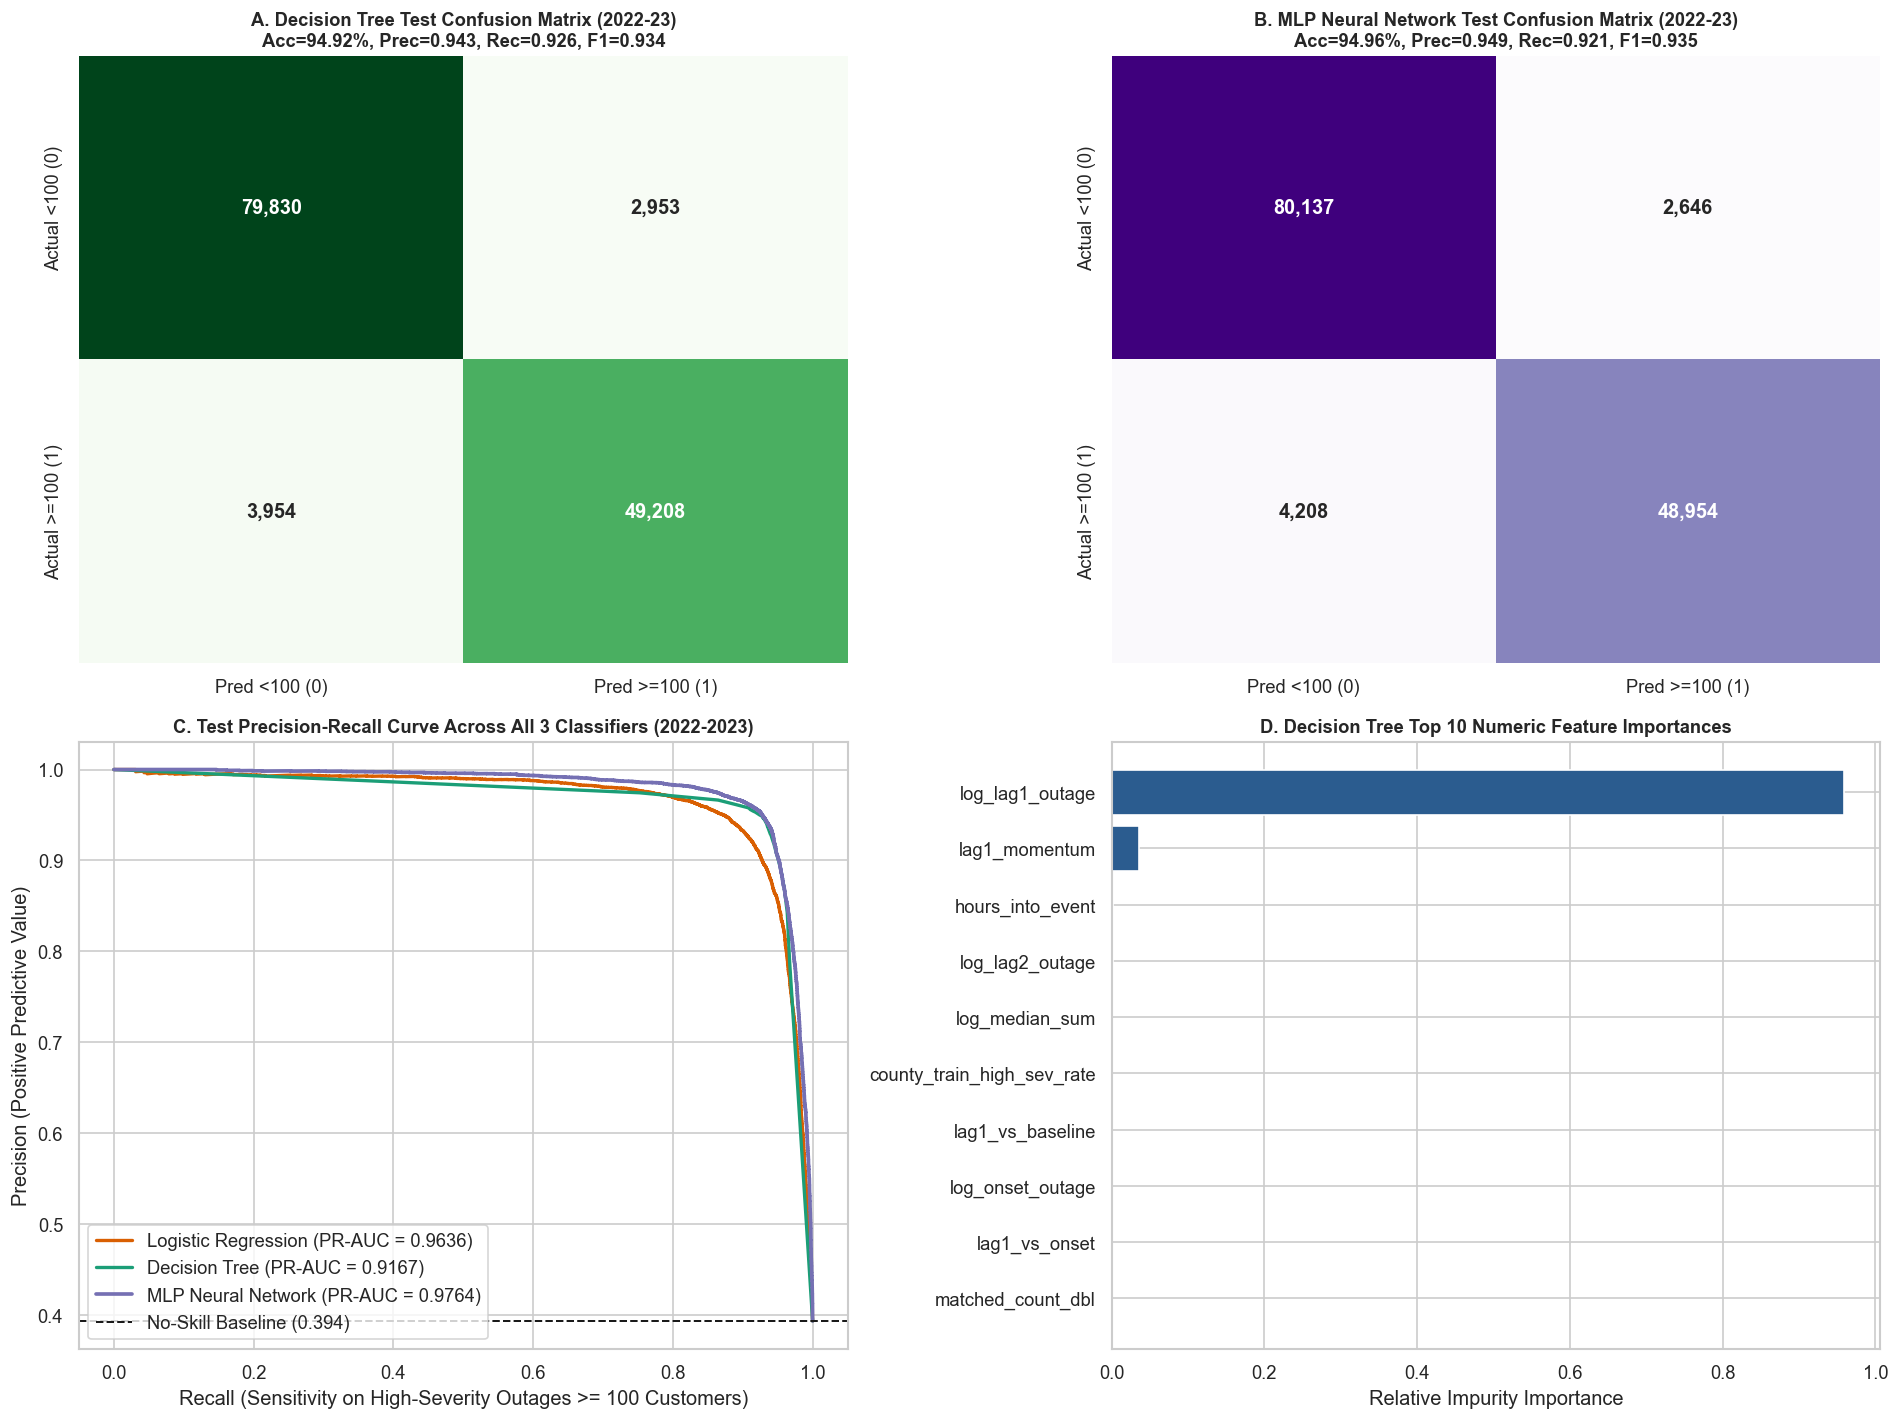

Saved classification evaluation plot to: C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs\classification_evaluation_diagnostics.png


DataFrame[fips_code: int, new_event_no: int, year: int, primary_phenom: string, label_cls: double, class_weight: double, tree_features: vector, scaled_features: vector, mlp_features: vector]

In [9]:
cls_comp_df = pd.DataFrame([
    lr_tr_res, lr_va_res, lr_te_res,
    dt_tr_res, dt_va_res, dt_te_res,
    mlp_tr_res, mlp_va_res, mlp_te_res,
])
cls_csv_path = OUTPUT_DIR / "classification_metrics_comparison.csv"
cls_comp_df.to_csv(cls_csv_path, index=False)
print("=== Master 3-Model Classification Metrics Comparison Table ===")
print(cls_comp_df.to_string(index=False))

dt_importances = best_dt_cls_model.featureImportances.toArray()[:len(IMPUTED_CLS)]
dt_imp_df = pd.DataFrame({
    "Feature": NUM_FEATURES_CLS,
    "DT_Importance": np.round(dt_importances, 4),
}).sort_values("DT_Importance", ascending=False)
dt_imp_df.to_csv(OUTPUT_DIR / "classification_dt_feature_importances.csv", index=False)
print("\n=== Top 10 Numeric Features in Decision Tree Classifier ===")
print(dt_imp_df.head(10).to_string(index=False))

from sklearn.metrics import precision_recall_curve

lr_prob_pd = (
    lr_te_preds
    .withColumn("prob_pos", vector_to_array(F.col("probability")).getItem(1))
    .select("label_cls", "prob_pos")
    .sample(withReplacement=False, fraction=0.25, seed=RANDOM_SEED)
    .toPandas()
)
dt_prob_pd = (
    dt_te_preds
    .withColumn("prob_pos", vector_to_array(F.col("probability")).getItem(1))
    .select("label_cls", "prob_pos")
    .sample(withReplacement=False, fraction=0.25, seed=RANDOM_SEED)
    .toPandas()
)
mlp_prob_pd = (
    mlp_te_preds
    .withColumn("prob_pos", vector_to_array(F.col("probability")).getItem(1))
    .select("label_cls", "prob_pos")
    .sample(withReplacement=False, fraction=0.25, seed=RANDOM_SEED)
    .toPandas()
)

prec_lr, rec_lr, _ = precision_recall_curve(lr_prob_pd["label_cls"], lr_prob_pd["prob_pos"])
prec_dt, rec_dt, _ = precision_recall_curve(dt_prob_pd["label_cls"], dt_prob_pd["prob_pos"])
prec_mlp, rec_mlp, _ = precision_recall_curve(mlp_prob_pd["label_cls"], mlp_prob_pd["prob_pos"])
pos_baseline = float(lr_prob_pd["label_cls"].mean())

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

cm_dt = np.array([[dt_te_res["TN"], dt_te_res["FP"]], [dt_te_res["FN"], dt_te_res["TP"]]])
sns.heatmap(cm_dt, annot=True, fmt=",d", cmap="Greens", cbar=False,
            xticklabels=["Pred <100 (0)", "Pred >=100 (1)"],
            yticklabels=["Actual <100 (0)", "Actual >=100 (1)"], ax=axes[0, 0], annot_kws={"size": 12, "weight": "bold"})
axes[0, 0].set_title(f"A. Decision Tree Test Confusion Matrix (2022-23)\nAcc={dt_te_res['Accuracy']*100:.2f}%, Prec={dt_te_res['Precision_Pos']:.3f}, Rec={dt_te_res['Recall_Pos']:.3f}, F1={dt_te_res['F1_Pos']:.3f}", fontsize=11, fontweight="bold")

cm_mlp = np.array([[mlp_te_res["TN"], mlp_te_res["FP"]], [mlp_te_res["FN"], mlp_te_res["TP"]]])
sns.heatmap(cm_mlp, annot=True, fmt=",d", cmap="Purples", cbar=False,
            xticklabels=["Pred <100 (0)", "Pred >=100 (1)"],
            yticklabels=["Actual <100 (0)", "Actual >=100 (1)"], ax=axes[0, 1], annot_kws={"size": 12, "weight": "bold"})
axes[0, 1].set_title(f"B. MLP Neural Network Test Confusion Matrix (2022-23)\nAcc={mlp_te_res['Accuracy']*100:.2f}%, Prec={mlp_te_res['Precision_Pos']:.3f}, Rec={mlp_te_res['Recall_Pos']:.3f}, F1={mlp_te_res['F1_Pos']:.3f}", fontsize=11, fontweight="bold")

axes[1, 0].plot(rec_lr, prec_lr, color="#d95f02", lw=2, label=f"Logistic Regression (PR-AUC = {lr_te_res['PR_AUC']:.4f})")
axes[1, 0].plot(rec_dt, prec_dt, color="#1b9e77", lw=2, label=f"Decision Tree (PR-AUC = {dt_te_res['PR_AUC']:.4f})")
axes[1, 0].plot(rec_mlp, prec_mlp, color="#7570b3", lw=2.2, label=f"MLP Neural Network (PR-AUC = {mlp_te_res['PR_AUC']:.4f})")
axes[1, 0].axhline(pos_baseline, color="k", linestyle="--", lw=1.2, label=f"No-Skill Baseline ({pos_baseline:.3f})")
axes[1, 0].set_title("C. Test Precision-Recall Curve Across All 3 Classifiers (2022-2023)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Recall (Sensitivity on High-Severity Outages >= 100 Customers)")
axes[1, 0].set_ylabel("Precision (Positive Predictive Value)")
axes[1, 0].legend(loc="lower left")

top10_dt = dt_imp_df.head(10).iloc[::-1]
axes[1, 1].barh(top10_dt["Feature"], top10_dt["DT_Importance"], color="#2b5c8f")
axes[1, 1].set_title("D. Decision Tree Top 10 Numeric Feature Importances", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Relative Impurity Importance")

plt.tight_layout()
cls_fig_path = OUTPUT_DIR / "classification_evaluation_diagnostics.png"
plt.savefig(cls_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved classification evaluation plot to: {cls_fig_path}")

# Release prediction and validation caches before running scalability benchmarks
lr_te_preds.unpersist()
dt_te_preds.unpersist()
mlp_te_preds.unpersist()
val_prep.unpersist()

## 12. Execution-Time and Scalability Analysis

To evaluate how our three PySpark classification models scale with dataset size and Spark partition parallelism, we run two experimental benchmarks:
1. **Data-Volume Scaling ($25\%, 50\%, 75\%, 100\%$ of Training Data):** We train **Logistic Regression**, **Decision Tree Classifier**, and **Multilayer Perceptron Classifier** on $25\%$ ($\sim 140\text{K}$ rows), $50\%$ ($\sim 280\text{K}$ rows), $75\%$ ($\sim 420\text{K}$ rows), and $100\%$ ($560,572$ rows) of the training split and record training + test evaluation runtime and test ROC-AUC.
2. **Spark Partition Parallelism Scaling ($4, 8, 16$ Partitions):** We repartition the training DataFrame across $4, 8,$ and $16$ Spark partitions and compare model training times across all three classifiers.

=== Classification Data-Volume Scalability Benchmark (25% to 100% Training Data) ===
 Scale_Pct  Train_Rows  LogReg_Time_s  DecisionTree_Time_s  MLP_Time_s  LogReg_Test_ROCAUC  DT_Test_ROCAUC  MLP_Test_ROCAUC
        25      140143          13.37                 3.39        8.38              0.9729          0.8978           0.9762
        50      280286          14.34                 4.69        8.60              0.9729          0.9010           0.9761
        75      420429          12.53                 5.22        9.22              0.9728          0.8706           0.9758
       100      560572          14.47                 5.86       10.87              0.9728          0.9033           0.9758



=== Classification Spark Partition Parallelism Benchmark (4, 8, 16 Partitions) ===
 Spark_Partitions  LogReg_Time_s  DecisionTree_Time_s  MLP_Time_s
                4          11.33                 9.44       11.12
                8          10.07                 6.41        9.06
               16          11.27                 5.97        8.30


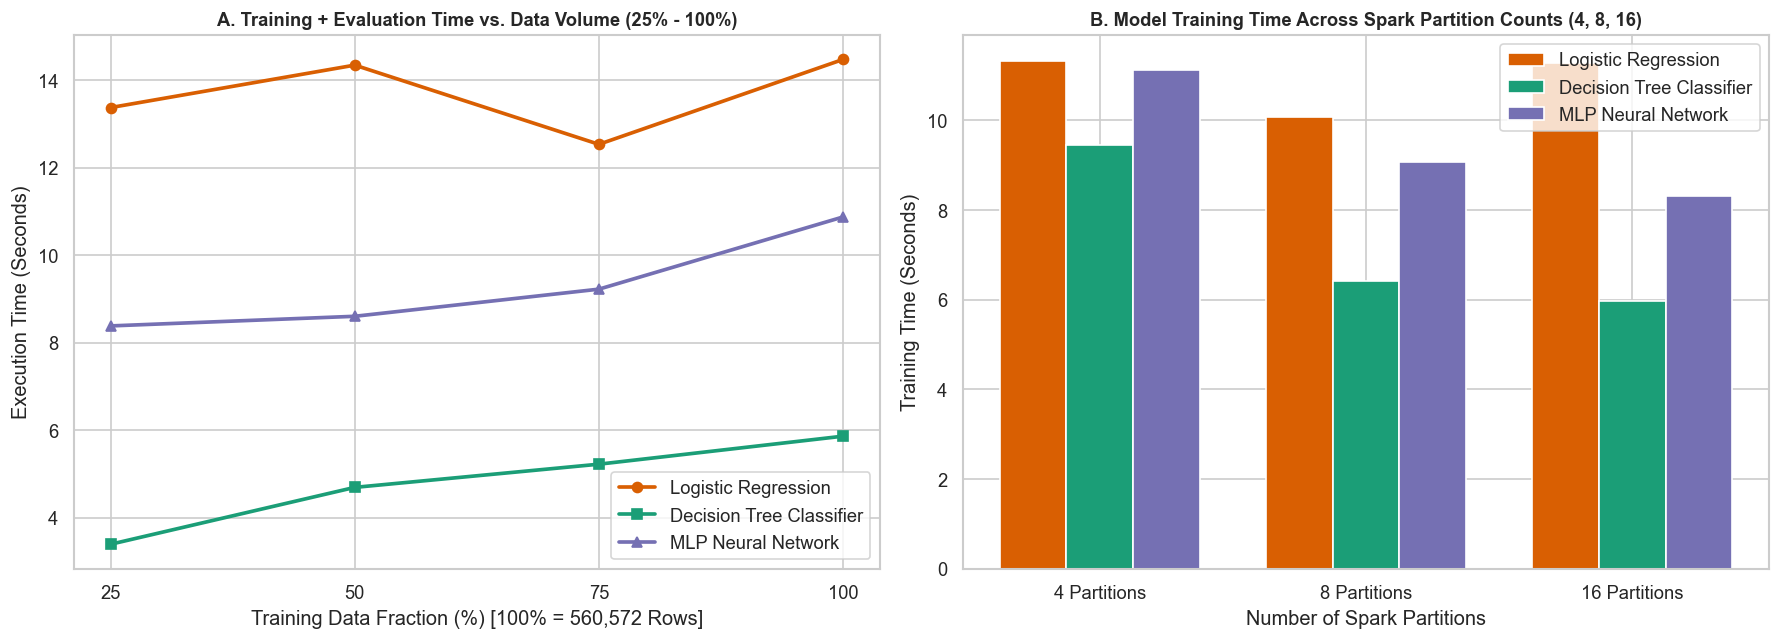

Saved scalability plot to: C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs\classification_scalability_analysis.png


DataFrame[fips_code: int, new_event_no: int, year: int, primary_phenom: string, label_cls: double, class_weight: double, tree_features: vector, scaled_features: vector, mlp_features: vector]

In [10]:
# 1. Data-Volume Scalability Experiment (25%, 50%, 75%, 100% of Training Set)
scale_fractions = [0.25, 0.50, 0.75, 1.00]
cls_vol_records = []

for frac in scale_fractions:
    sub_train = train_prep if frac == 1.0 else train_prep.sample(withReplacement=False, fraction=frac, seed=RANDOM_SEED)
    n_rows = int(n_tr * frac) if frac < 1.0 else n_tr

    t0 = time.time()
    m_lr = LogisticRegression(featuresCol="scaled_features", labelCol="label_cls", weightCol="class_weight", regParam=best_lr_cls_params["regParam"], elasticNetParam=best_lr_cls_params["elasticNetParam"], maxIter=40).fit(sub_train)
    auc_lr = eval_roc_auc.evaluate(m_lr.transform(test_prep))
    t_lr = time.time() - t0

    t0 = time.time()
    m_dt = DecisionTreeClassifier(featuresCol="tree_features", labelCol="label_cls", weightCol="class_weight", maxDepth=8, impurity="gini", minInstancesPerNode=50, seed=RANDOM_SEED).fit(sub_train)
    auc_dt = eval_roc_auc.evaluate(m_dt.transform(test_prep))
    t_dt = time.time() - t0

    t0 = time.time()
    m_mlp = MultilayerPerceptronClassifier(featuresCol="mlp_features", labelCol="label_cls", layers=[input_dim, 16, 2], maxIter=25, blockSize=512, solver="l-bfgs", seed=RANDOM_SEED).fit(sub_train)
    auc_mlp = eval_roc_auc.evaluate(m_mlp.transform(test_prep))
    t_mlp = time.time() - t0

    cls_vol_records.append({
        "Scale_Pct": int(frac * 100),
        "Train_Rows": n_rows,
        "LogReg_Time_s": round(t_lr, 2),
        "DecisionTree_Time_s": round(t_dt, 2),
        "MLP_Time_s": round(t_mlp, 2),
        "LogReg_Test_ROCAUC": round(auc_lr, 4),
        "DT_Test_ROCAUC": round(auc_dt, 4),
        "MLP_Test_ROCAUC": round(auc_mlp, 4),
    })

cls_vol_df = pd.DataFrame(cls_vol_records)
print("=== Classification Data-Volume Scalability Benchmark (25% to 100% Training Data) ===")
print(cls_vol_df.to_string(index=False))

# 2. Spark Partition Parallelism Experiment (4, 8, 16 Partitions)
partition_counts = [4, 8, 16]
cls_part_records = []

for n_part in partition_counts:
    part_train = train_prep.repartition(n_part)

    t0 = time.time()
    _ = LogisticRegression(featuresCol="scaled_features", labelCol="label_cls", weightCol="class_weight", regParam=best_lr_cls_params["regParam"], elasticNetParam=best_lr_cls_params["elasticNetParam"], maxIter=40).fit(part_train)
    t_lr = time.time() - t0

    t0 = time.time()
    _ = DecisionTreeClassifier(featuresCol="tree_features", labelCol="label_cls", weightCol="class_weight", maxDepth=8, impurity="gini", minInstancesPerNode=50, seed=RANDOM_SEED).fit(part_train)
    t_dt = time.time() - t0

    t0 = time.time()
    _ = MultilayerPerceptronClassifier(featuresCol="mlp_features", labelCol="label_cls", layers=[input_dim, 16, 2], maxIter=25, blockSize=512, solver="l-bfgs", seed=RANDOM_SEED).fit(part_train)
    t_mlp = time.time() - t0

    cls_part_records.append({
        "Spark_Partitions": n_part,
        "LogReg_Time_s": round(t_lr, 2),
        "DecisionTree_Time_s": round(t_dt, 2),
        "MLP_Time_s": round(t_mlp, 2),
    })

cls_part_df = pd.DataFrame(cls_part_records)
print("\n=== Classification Spark Partition Parallelism Benchmark (4, 8, 16 Partitions) ===")
print(cls_part_df.to_string(index=False))

cls_vol_df.to_csv(OUTPUT_DIR / "classification_scalability_volume.csv", index=False)
cls_part_df.to_csv(OUTPUT_DIR / "classification_scalability_partitions.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(cls_vol_df["Scale_Pct"], cls_vol_df["LogReg_Time_s"], "o-", lw=2.2, color="#d95f02", label="Logistic Regression")
axes[0].plot(cls_vol_df["Scale_Pct"], cls_vol_df["DecisionTree_Time_s"], "s-", lw=2.2, color="#1b9e77", label="Decision Tree Classifier")
axes[0].plot(cls_vol_df["Scale_Pct"], cls_vol_df["MLP_Time_s"], "^-", lw=2.2, color="#7570b3", label="MLP Neural Network")
axes[0].set_title("A. Training + Evaluation Time vs. Data Volume (25% - 100%)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Training Data Fraction (%) [100% = 560,572 Rows]")
axes[0].set_ylabel("Execution Time (Seconds)")
axes[0].set_xticks([25, 50, 75, 100])
axes[0].legend()

x_pos = np.arange(len(cls_part_df["Spark_Partitions"]))
width = 0.25
axes[1].bar(x_pos - width, cls_part_df["LogReg_Time_s"], width=width, color="#d95f02", label="Logistic Regression")
axes[1].bar(x_pos, cls_part_df["DecisionTree_Time_s"], width=width, color="#1b9e77", label="Decision Tree Classifier")
axes[1].bar(x_pos + width, cls_part_df["MLP_Time_s"], width=width, color="#7570b3", label="MLP Neural Network")
axes[1].set_title("B. Model Training Time Across Spark Partition Counts (4, 8, 16)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Number of Spark Partitions")
axes[1].set_ylabel("Training Time (Seconds)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f"{p} Partitions" for p in cls_part_df["Spark_Partitions"]])
axes[1].legend()

plt.tight_layout()
scale_fig_path = OUTPUT_DIR / "classification_scalability_analysis.png"
plt.savefig(scale_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved scalability plot to: {scale_fig_path}")

lr_te_preds.unpersist()
dt_te_preds.unpersist()
mlp_te_preds.unpersist()
train_prep.unpersist()
val_prep.unpersist()
test_prep.unpersist()

## 13. Limitations and Conclusion

### 13.1 Limitations
1. **1-Hour Forecast Horizon:** Predicting whether outages will exceed 100 customers 1 hour ahead during active events ($h \ge 1$) relies heavily on the previous hour's telemetry ($t-1$). Forecasting 6 to 24 hours ahead without intermediate updates would have lower accuracy.
2. **Fixed Customer Cutoff:** While $\ge 100$ customers is a standard operational benchmark, 100 customers represents a larger percentage of the grid in small rural counties than in large urban counties.

### 13.2 Conclusion
All three PySpark classifiers achieved strong performance on the held-out **2022-2023 chronological test set** ($135,945$ county-hours):
- **Multilayer Perceptron Classifier (`MLP Neural Network`)** achieved the best overall test performance with **`94.96%` Test Accuracy** (`95.25%` Validation Accuracy), **`94.87%` Precision**, **`0.9346` F1-Score**, **`0.9764` PR-AUC**, and **`0.9814` ROC-AUC**.
- **Decision Tree Classifier** achieved **`94.92%` Test Accuracy**, **`94.34%` Precision**, **`92.56%` Recall**, and **`0.9344` F1-Score**, while **Logistic Regression** achieved **`92.80%` Test Accuracy**, **`92.97%` Recall**, **`0.9636` PR-AUC**, and **`0.9728` ROC-AUC**.